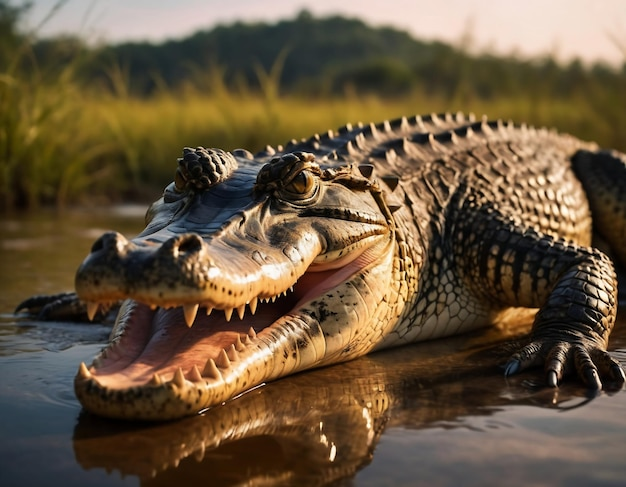

In [1]:
import os
from pathlib import Path
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

fig_dir = Path("report/figures")
if not fig_dir.exists():
    for parent in Path.cwd().parents:
        candidate = parent / "report" / "figures"
        if (parent / "pyproject.toml").exists() or (parent / "Taskfile.yml").exists():
            fig_dir = candidate
            break
fig_dir.mkdir(parents=True, exist_ok=True)

crocodile = Image.open("2.jpg")
crocodile

In [2]:
import numpy as np
arr = np.mean(np.array(crocodile), axis=2)
arr

array([[101.        , 105.        , 110.        , ..., 221.66666667,
        221.66666667, 221.66666667],
       [ 96.        ,  99.        , 105.        , ..., 221.66666667,
        221.66666667, 221.66666667],
       [ 85.33333333,  89.33333333,  94.33333333, ..., 221.66666667,
        221.66666667, 221.66666667],
       ...,
       [ 36.33333333,  36.33333333,  36.33333333, ...,  70.66666667,
         70.66666667,  70.66666667],
       [ 35.33333333,  35.33333333,  36.33333333, ...,  67.66666667,
         67.66666667,  67.66666667],
       [ 35.33333333,  35.33333333,  35.33333333, ...,  65.66666667,
         65.66666667,  65.66666667]], shape=(487, 626))

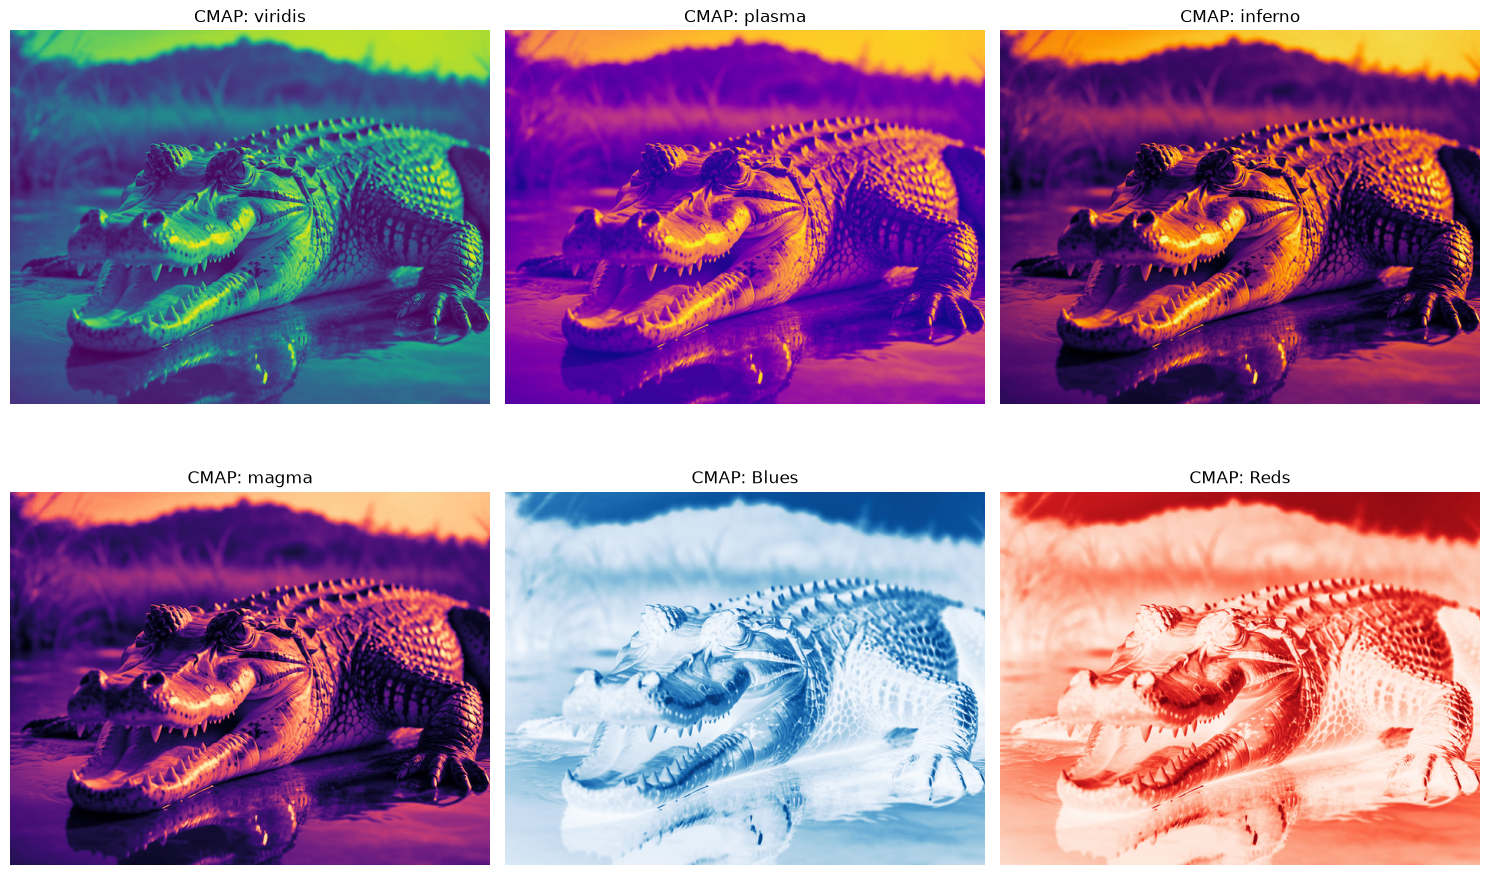

In [3]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
cmaps = ['viridis', 'plasma', 'inferno', 'magma', 'Blues', 'Reds']

for i, cmap in enumerate(cmaps):
    row = i // 3
    col = i % 3
    axs[row, col].imshow(arr, cmap=cmap)
    axs[row, col].set_title(f'CMAP: {cmap}', fontsize=12)
    axs[row, col].axis('off')

plt.tight_layout()
plt.savefig(fig_dir / "fig_3_1.png", bbox_inches="tight", dpi=300)
plt.show()

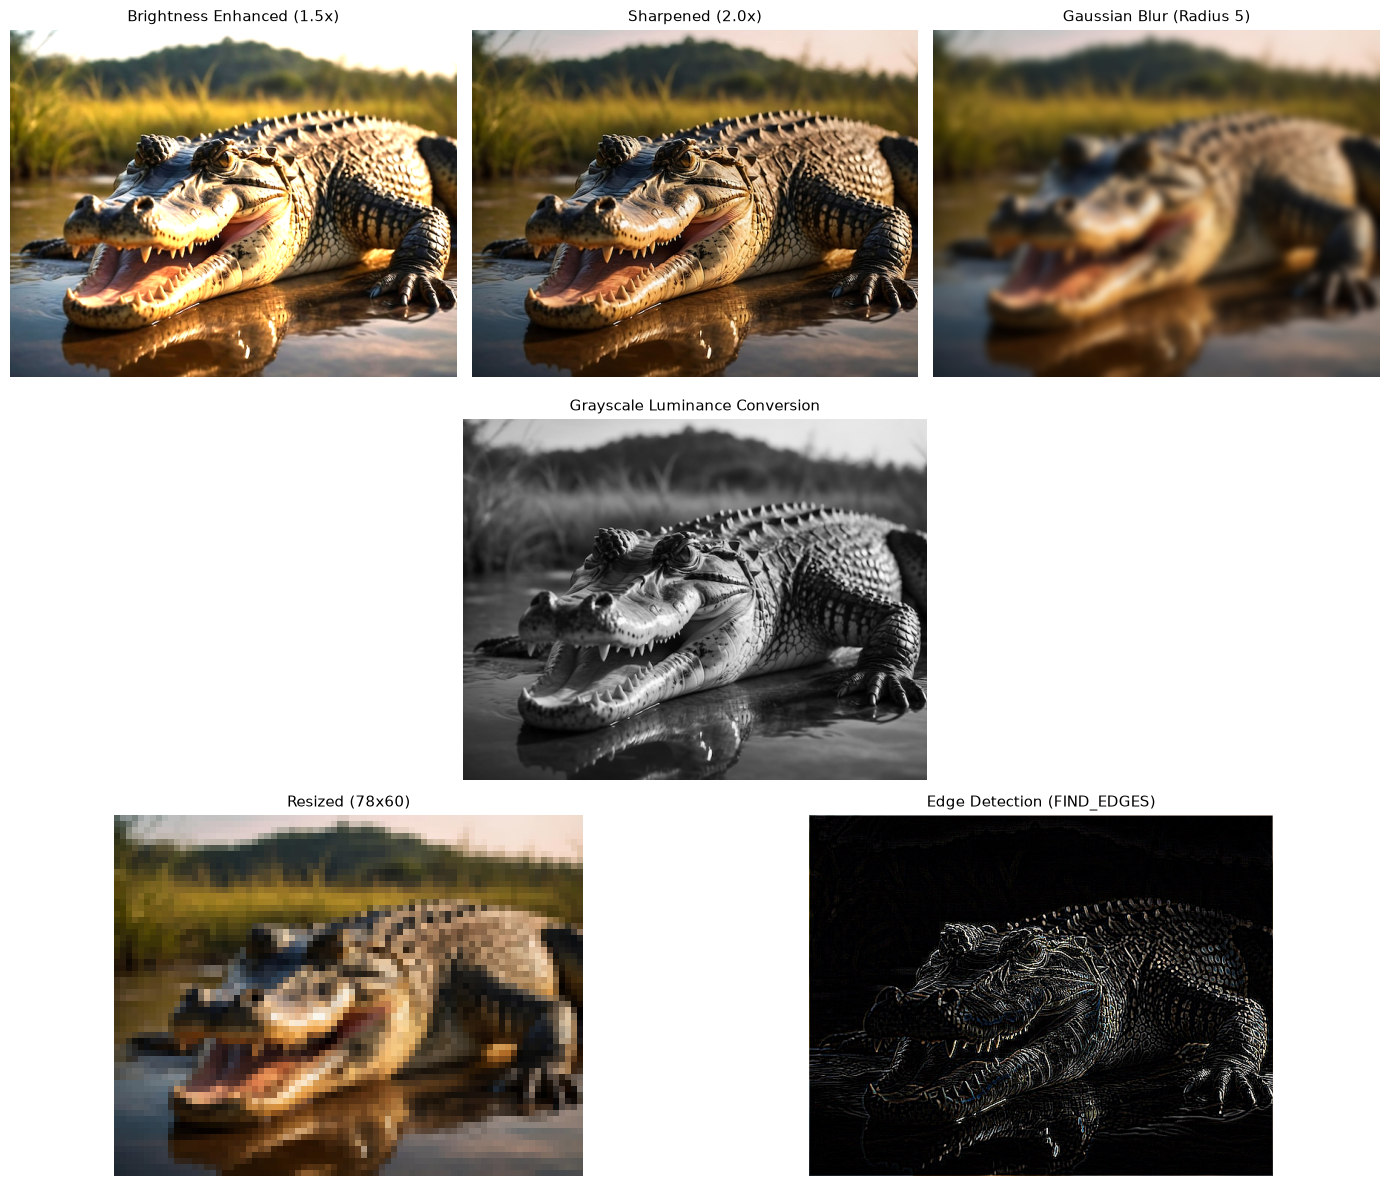

In [4]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(14, 12))
gs = GridSpec(3, 6, figure=fig)

# Row 1: 3 subplots
ax1 = fig.add_subplot(gs[0, 0:2])
ax2 = fig.add_subplot(gs[0, 2:4])
ax3 = fig.add_subplot(gs[0, 4:6])

# Row 2: 1 subplot in the 2nd row (centered)
ax4 = fig.add_subplot(gs[1, 1:5])

# Row 3: 2 subplots in the 3rd row
ax5 = fig.add_subplot(gs[2, 0:3])
ax6 = fig.add_subplot(gs[2, 3:6])

# 1. Brightness
enhancer = ImageEnhance.Brightness(crocodile)
brightened = enhancer.enhance(1.5)
ax1.imshow(brightened)
ax1.set_title('Brightness Enhanced (1.5x)', fontsize=11)
ax1.axis('off')

# 2. Sharpening
enhancer = ImageEnhance.Sharpness(crocodile)
sharpened = enhancer.enhance(2.0)
ax2.imshow(sharpened)
ax2.set_title('Sharpened (2.0x)', fontsize=11)
ax2.axis('off')

# 3. Blur
blurred = crocodile.filter(ImageFilter.GaussianBlur(radius=5))
ax3.imshow(blurred)
ax3.set_title('Gaussian Blur (Radius 5)', fontsize=11)
ax3.axis('off')

# 4. Gray Scale (Row 2 center)
grayscale = ImageOps.grayscale(crocodile)
ax4.imshow(grayscale, cmap='gray')
ax4.set_title('Grayscale Luminance Conversion', fontsize=11)
ax4.axis('off')

# 5. Resize
resized = crocodile.resize((crocodile.width // 8, crocodile.height // 8))
ax5.imshow(resized)
ax5.set_title(f'Resized ({resized.width}x{resized.height})', fontsize=11)
ax5.axis('off')

# 6. Edge Detection
edges = crocodile.filter(ImageFilter.FIND_EDGES)
ax6.imshow(edges)
ax6.set_title('Edge Detection (FIND_EDGES)', fontsize=11)
ax6.axis('off')

plt.tight_layout()
plt.savefig(fig_dir / "fig_3_2.png", bbox_inches="tight", dpi=300)
plt.show()